In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

In [7]:
# -------------------------------------------------------------
# 1. LOAD DATA
# -------------------------------------------------------------
#FILE_PATH = C:\Users\vimit\OneDrive\Desktop\data science\miniproject\sri_lanka_flood_risk_modeled.csv

df = pd.read_csv('sri_lanka_flood_risk_modeled.csv')
print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')

#https://www.kaggle.com/datasets/rasindupramith/sri-lanka-district-climate-and-flood-risk20152024/data

Dataset shape: 91,325 rows × 19 columns


In [8]:
# 2. DATA OVERVIEW
# -------------------------------------------------------------
print('\n=== First 5 rows ===')
display(df.head())

print('\n=== Data types and missing values ===')
info = pd.DataFrame({
    'dtype': df.dtypes,
    'non_null': df.notna().sum(),
    'missing': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(2),
    'unique': df.nunique()
})
display(info)

print('\n=== Descriptive statistics (numeric) ===')
display(df.describe().T)

print('\n=== Descriptive statistics (categorical) ===')
display(df.describe(include='object').T)


=== First 5 rows ===


,date,precipitation_sum,rain_sum,soil_moisture_0_to_7cm_mean,soil_moisture_7_to_28cm_mean,temperature_2m_max,wind_speed_10m_max,district,latitude,longitude,province,climatic_zone,rain_24h,rain_48h,rain_72h,soil_saturation_index,year,flood_risk_score,flood_category
0,2015-01-01,1.600,1.600,0.375,0.378,29.100,8.200,Ampara,7.291,81.672,Eastern,Dry,1.600,1.600,1.600,0.376,2015,0.200,Low Risk (Normal)
1,2015-01-02,1.300,1.300,0.372,0.373,28.900,7.900,Ampara,7.291,81.672,Eastern,Dry,1.300,2.900,2.900,0.372,2015,0.300,Low Risk (Normal)
2,2015-01-03,0.000,0.000,0.361,0.368,29.400,11.400,Ampara,7.291,81.672,Eastern,Dry,0.000,1.300,2.900,0.364,2015,0.300,Low Risk (Normal)
3,2015-01-04,0.200,0.200,0.349,0.360,29.100,13.900,Ampara,7.291,81.672,Eastern,Dry,0.200,0.200,1.500,0.353,2015,0.100,Low Risk (Normal)
4,2015-01-05,3.300,3.300,0.349,0.353,27.800,16.500,Ampara,7.291,81.672,Eastern,Dry,3.300,3.500,3.500,0.351,2015,0.300,Low Risk (Normal)



=== Data types and missing values ===


,dtype,non_null,missing,missing_%,unique
date,str,91325,0,0.000,3653
precipitation_sum,float64,91325,0,0.000,879
rain_sum,float64,91325,0,0.000,879
soil_moisture_0_to_7cm_mean,float64,91325,0,0.000,506
soil_moisture_7_to_28cm_mean,float64,91325,0,0.000,494
temperature_2m_max,float64,91325,0,0.000,253
wind_speed_10m_max,float64,91325,0,0.000,506
district,str,91325,0,0.000,25
latitude,float64,91325,0,0.000,25
longitude,float64,91325,0,0.000,25



=== Descriptive statistics (numeric) ===


,count,mean,std,min,25%,50%,75%,max
precipitation_sum,"91,325.000",5.547,10.225,0.000,0.200,1.800,6.700,321.800
rain_sum,"91,325.000",5.547,10.225,0.000,0.200,1.800,6.700,321.800
soil_moisture_0_to_7cm_mean,"91,325.000",0.332,0.127,0.011,0.233,0.350,0.443,0.518
soil_moisture_7_to_28cm_mean,"91,325.000",0.327,0.121,0.017,0.223,0.334,0.430,0.518
temperature_2m_max,"91,325.000",29.901,3.253,14.700,28.400,29.800,31.700,40.400
wind_speed_10m_max,"91,325.000",17.157,6.948,2.500,12.100,16.200,21.000,76.000
latitude,"91,325.000",7.588,1.033,5.955,6.927,7.291,8.311,9.662
longitude,"91,325.000",80.588,0.533,79.839,80.221,80.498,81.019,81.675
rain_24h,"91,325.000",5.547,10.225,0.000,0.200,1.800,6.700,321.800
rain_48h,"91,325.000",11.089,17.677,0.000,0.900,4.600,14.600,481.500



=== Descriptive statistics (categorical) ===


,count,unique,top,freq
date,91325,3653,2015-01-01,25
district,91325,25,Ampara,3653
province,91325,9,Northern,18265
climatic_zone,91325,3,Dry,43836
flood_category,91325,4,Low Risk (Normal),84693


In [9]:

# -------------------------------------------------------------
# 3. STRUCTURE: CATEGORICAL FEATURES
# -------------------------------------------------------------
cat_cols = ['district', 'province', 'climatic_zone', 'flood_category']
for col in cat_cols:
    print(f'\n--- {col} ({df[col].nunique()} unique) ---')
    print(df[col].value_counts())


--- district (25 unique) ---
district
Ampara          3653
Anuradhapura    3653
Badulla         3653
Batticaloa      3653
Colombo         3653
Galle           3653
Gampaha         3653
Hambantota      3653
Jaffna          3653
Kalutara        3653
Kandy           3653
Kegalle         3653
Kilinochchi     3653
Kurunegala      3653
Mannar          3653
Matale          3653
Matara          3653
Monaragala      3653
Mullaitivu      3653
Nuwara Eliya    3653
Polonnaruwa     3653
Puttalam        3653
Ratnapura       3653
Trincomalee     3653
Vavuniya        3653
Name: count, dtype: int64

--- province (9 unique) ---
province
Northern         18265
Eastern          10959
Western          10959
Southern         10959
Central          10959
North Central     7306
Uva               7306
Sabaragamuwa      7306
North Western     7306
Name: count, dtype: int64

--- climatic_zone (3 unique) ---
climatic_zone
Dry             43836
Wet             32877
Intermediate    14612
Name: count, dtype: int64

In [10]:
# -------------------------------------------------------------
# 4. TIME RANGE
# -------------------------------------------------------------
df['date'] = pd.to_datetime(df['date'])
print(f'\nPeriod: {df["date"].min().date()} → {df["date"].max().date()}')
print(f'Years: {sorted(df["year"].unique())}')


Period: 2015-01-01 → 2024-12-31
Years: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [11]:
# Check duplicates
dups = df.duplicated(subset=['date', 'district']).sum()
print(f'\nDuplicates by (date, district): {dups}')


Duplicates by (date, district): 0


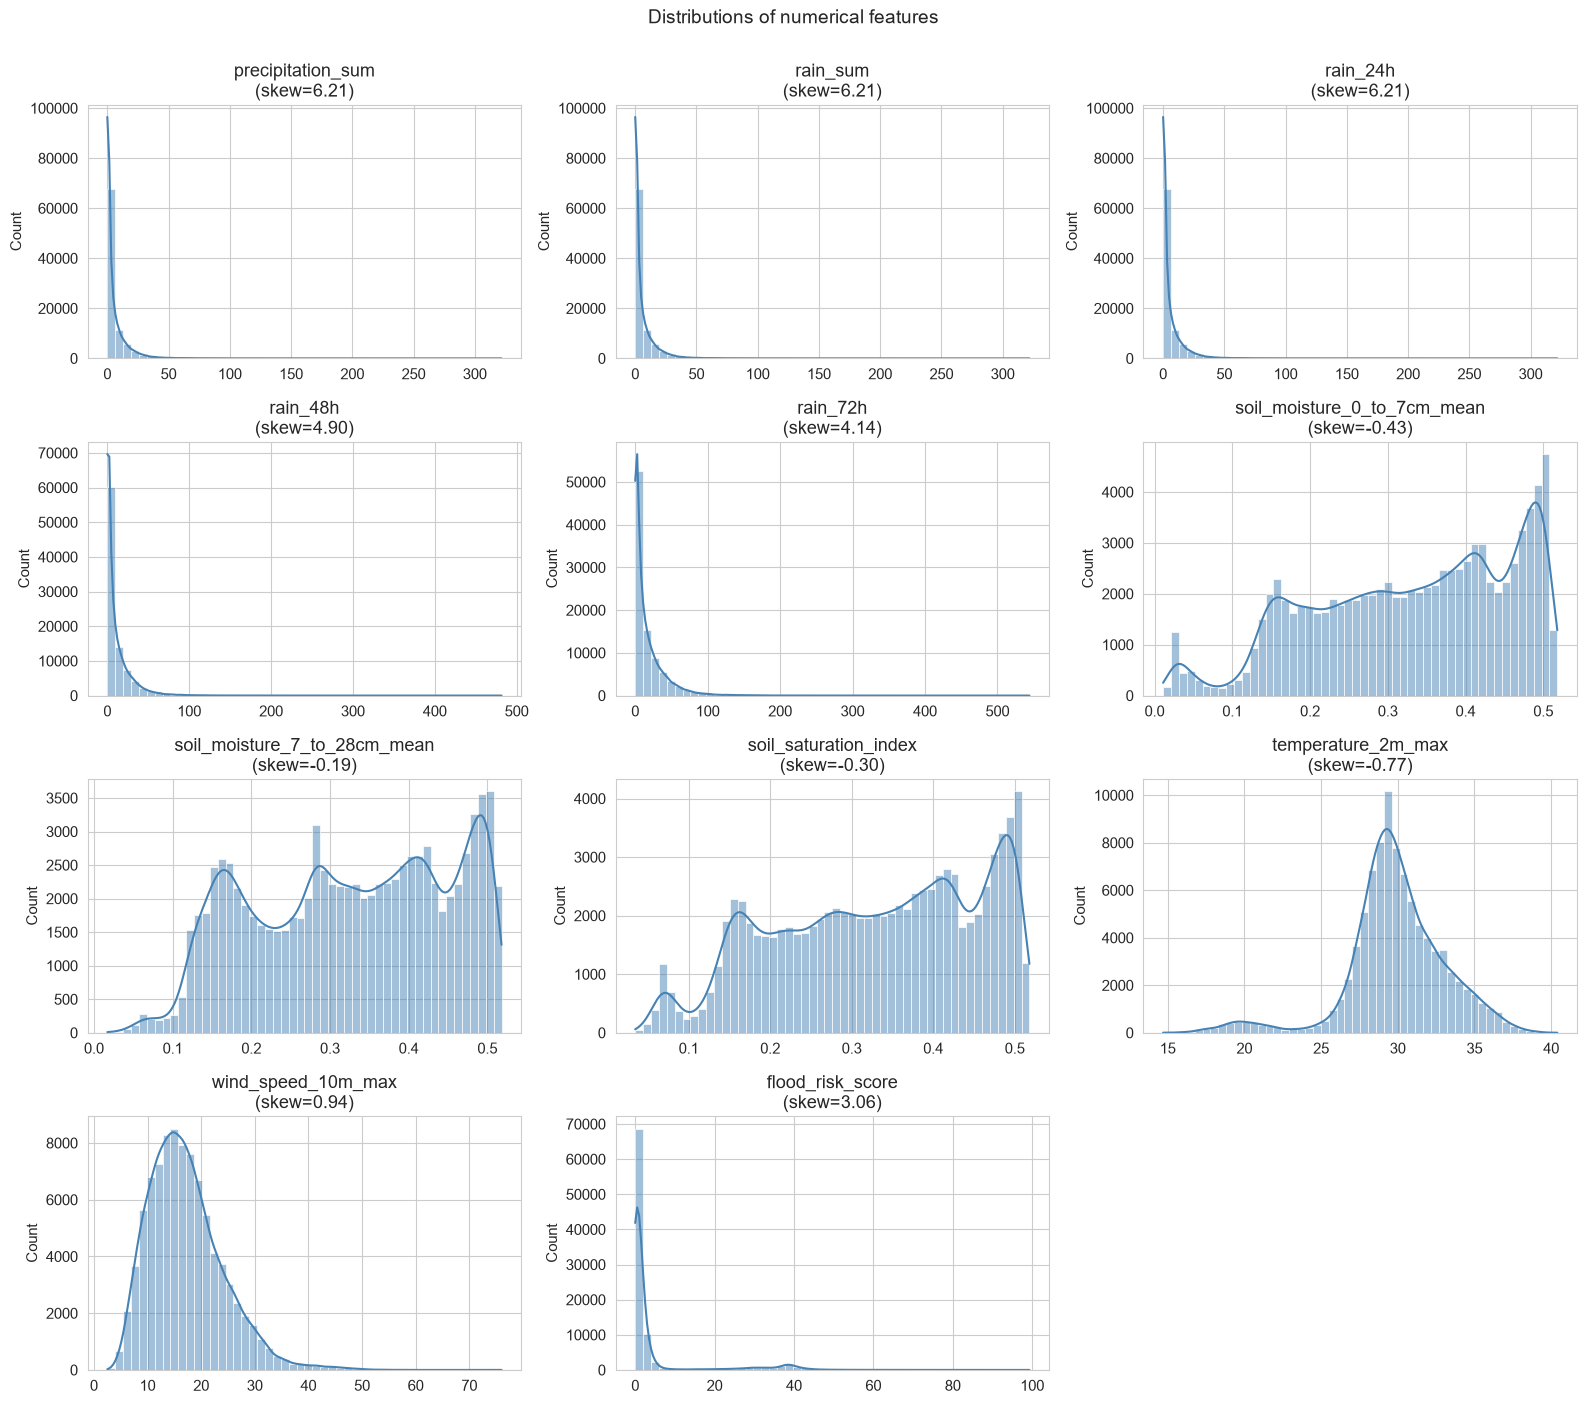

In [12]:
# -------------------------------------------------------------
# 5. NUMERICAL FEATURE DISTRIBUTIONS
# -------------------------------------------------------------
num_cols = ['precipitation_sum', 'rain_sum', 'rain_24h', 'rain_48h', 'rain_72h',
            'soil_moisture_0_to_7cm_mean', 'soil_moisture_7_to_28cm_mean',
            'soil_saturation_index', 'temperature_2m_max', 'wind_speed_10m_max',
            'flood_risk_score']

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=50, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'{col}\n(skew={df[col].skew():.2f})')
    axes[i].set_xlabel('')
for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')
plt.suptitle('Distributions of numerical features', y=1.001, fontsize=14)
plt.tight_layout()
plt.show()

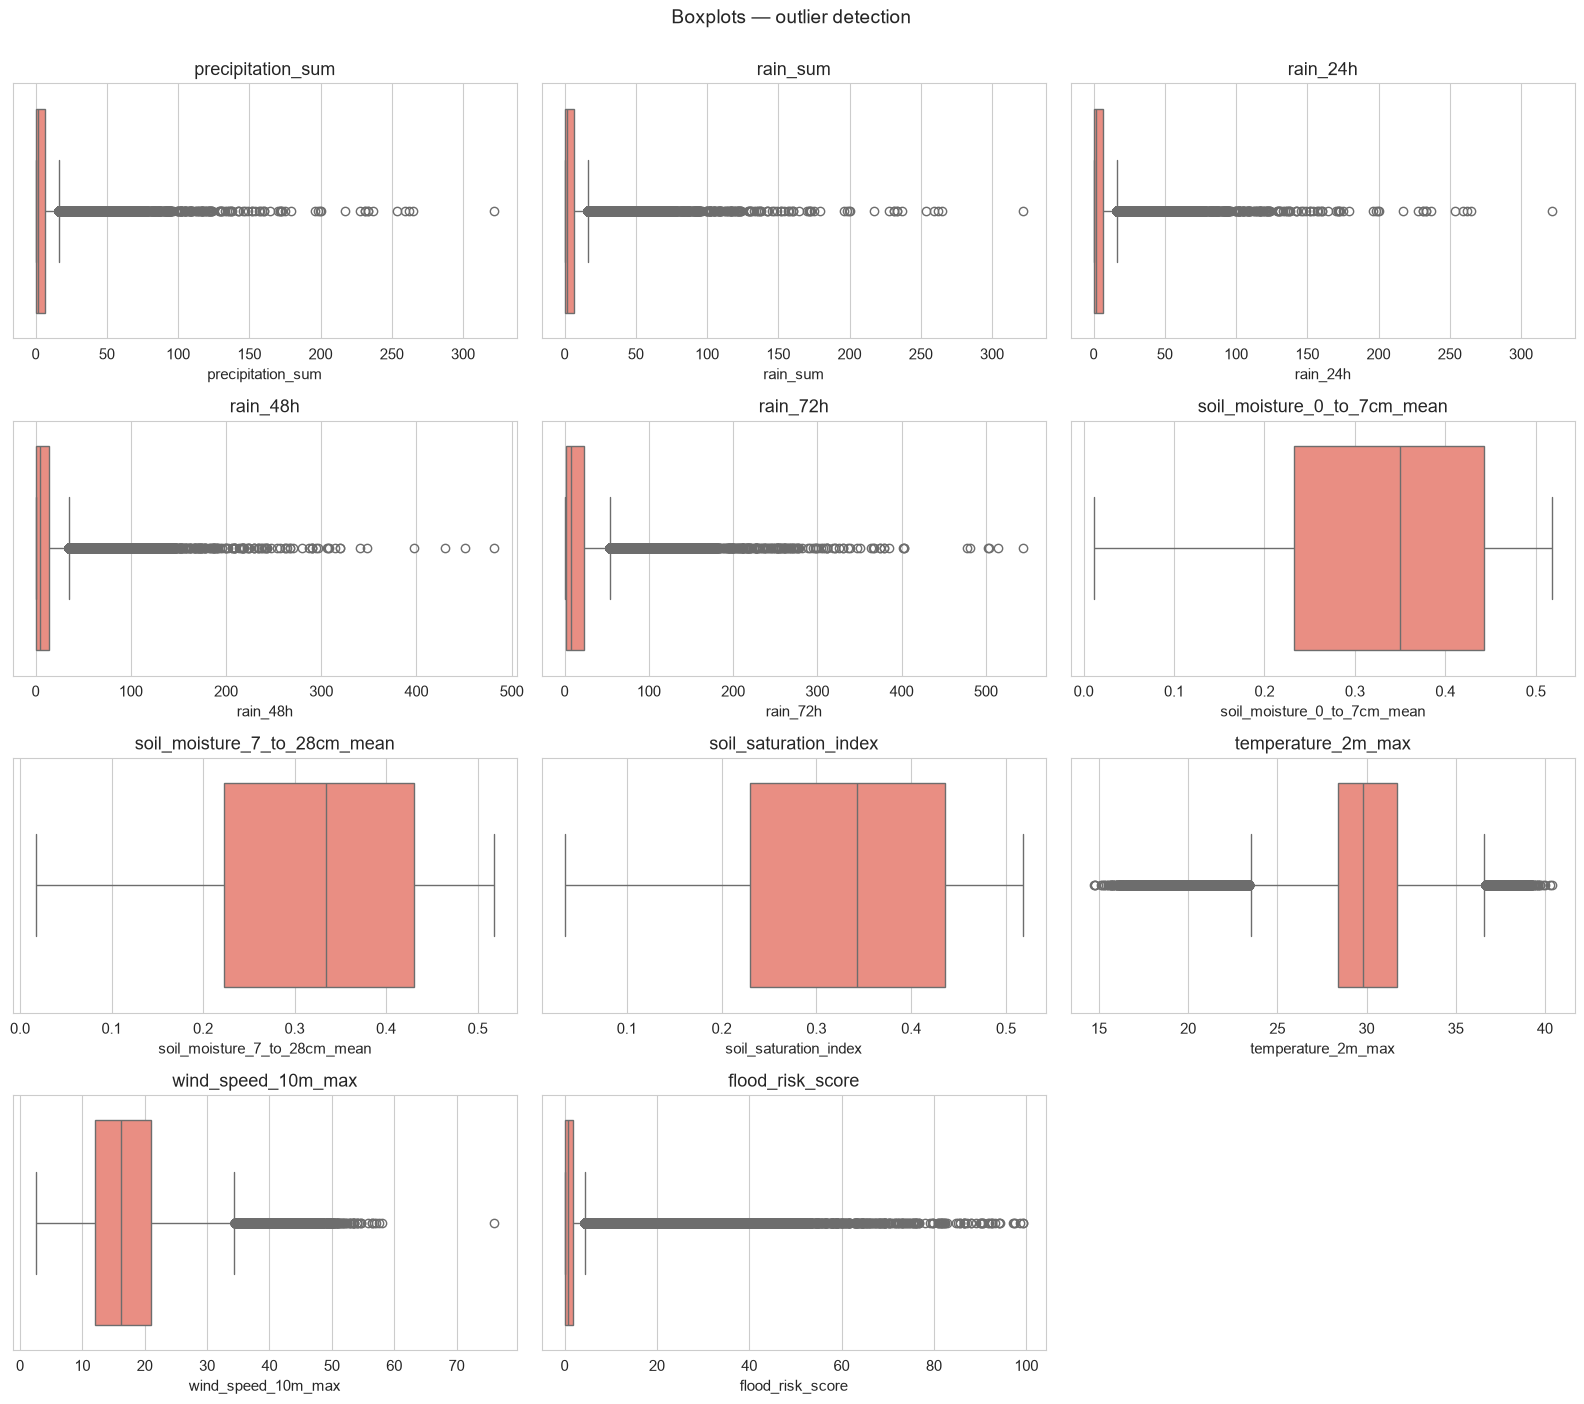

In [13]:
# Boxplots — outliers
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i], color='salmon')
    axes[i].set_title(col)
for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')
plt.suptitle('Boxplots — outlier detection', y=1.001, fontsize=14)
plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Frequency of risk categories')

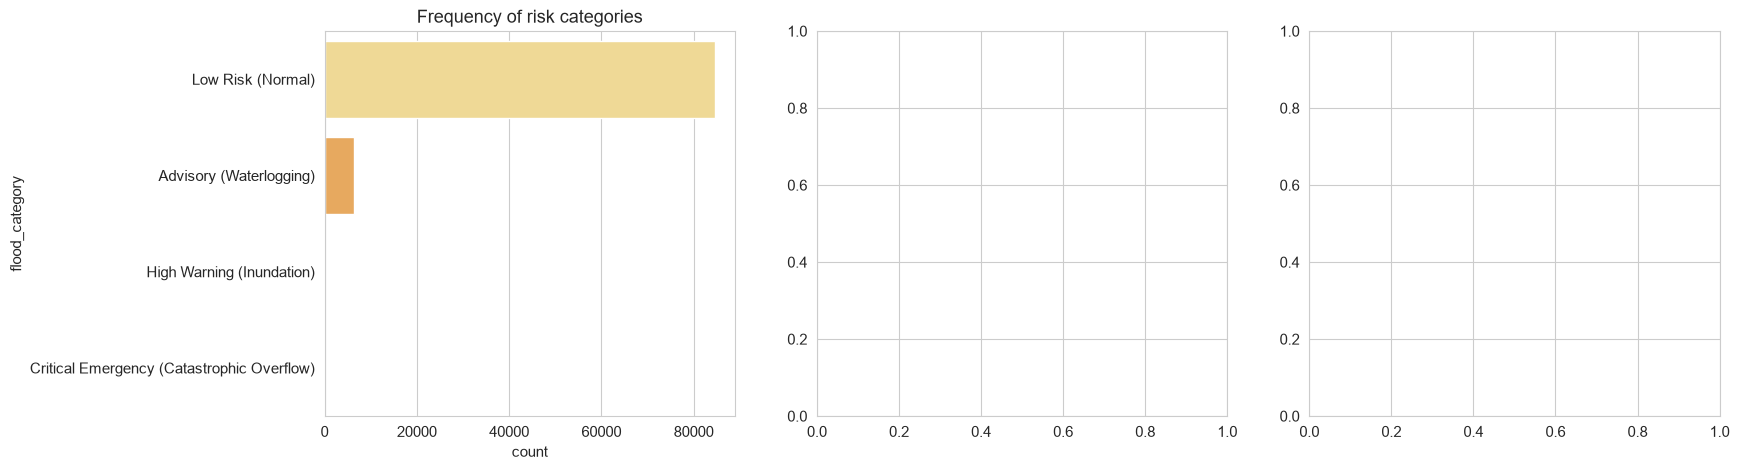

In [14]:
# -------------------------------------------------------------
# 6. TARGET VARIABLE: flood_category
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Frequencies
order = df['flood_category'].value_counts().index
sns.countplot(data=df, y='flood_category', order=order, ax=axes[0], palette='YlOrRd')
axes[0].set_title('Frequency of risk categories')

In [15]:
# Proportions
df['flood_category'].value_counts(normalize=True).plot.pie(
    autopct='%1.1f%%', ax=axes[1], ylabel='', colors=sns.color_palette('YlOrRd', 5))
axes[1].set_title('Proportions of categories')

Text(0.5, 1.0, 'Proportions of categories')

In [16]:
# Score by category
sns.boxplot(data=df, x='flood_category', y='flood_risk_score',
            order=order, ax=axes[2], palette='YlOrRd')
axes[2].set_title('flood_risk_score by category')
axes[2].tick_params(axis='x', rotation=30)

In [17]:
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

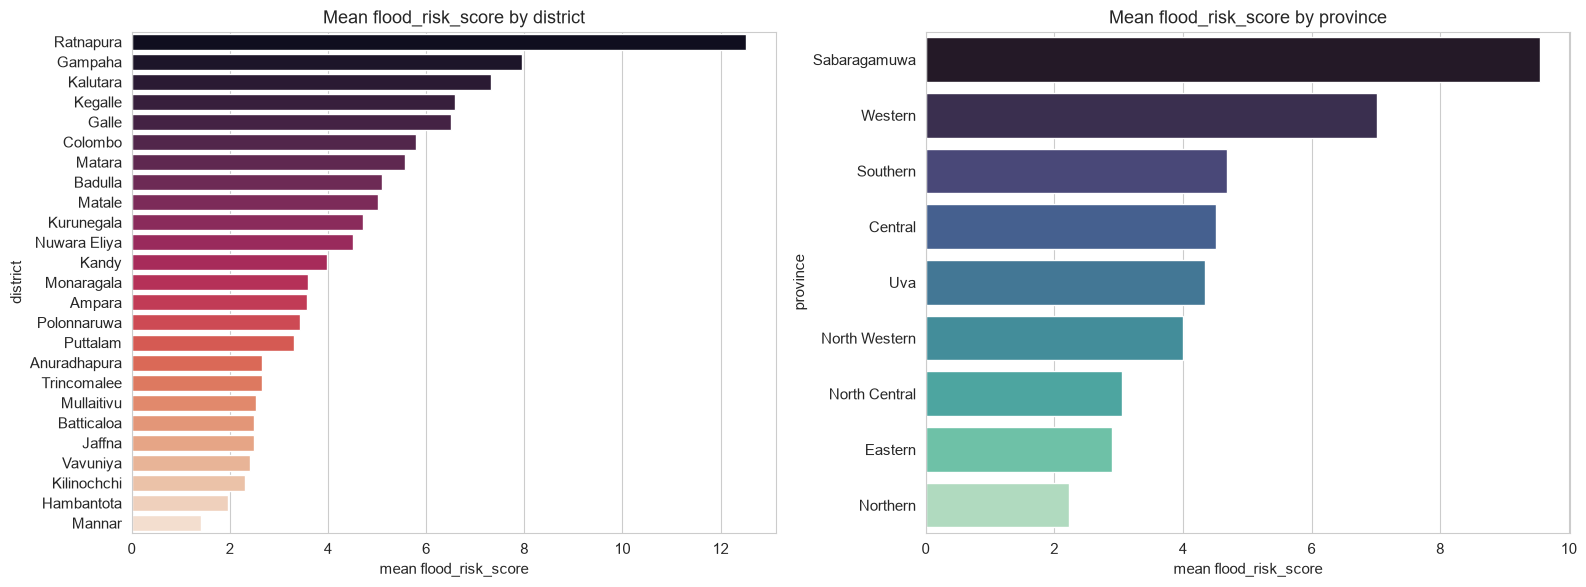

In [18]:
# -------------------------------------------------------------
# 7. GEOGRAPHY: RISK BY DISTRICT AND PROVINCE
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

dist_risk = (df.groupby('district')['flood_risk_score'].mean()
               .sort_values(ascending=False))
sns.barplot(x=dist_risk.values, y=dist_risk.index, ax=axes[0], palette='rocket')
axes[0].set_title('Mean flood_risk_score by district')
axes[0].set_xlabel('mean flood_risk_score')

prov_risk = (df.groupby('province')['flood_risk_score'].mean()
               .sort_values(ascending=False))
sns.barplot(x=prov_risk.values, y=prov_risk.index, ax=axes[1], palette='mako')
axes[1].set_title('Mean flood_risk_score by province')
axes[1].set_xlabel('mean flood_risk_score')

plt.tight_layout()
plt.show()

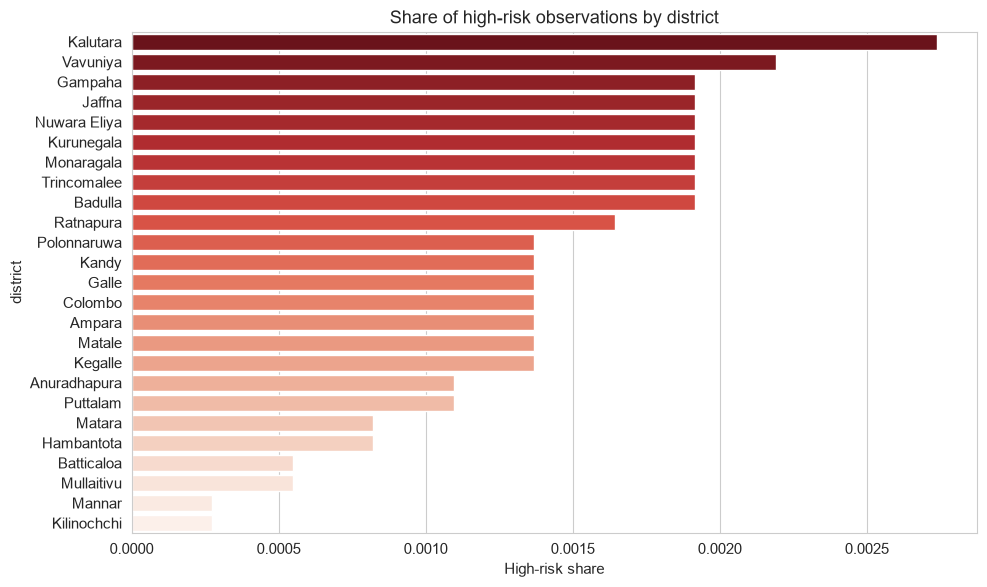

In [19]:
# Share of high risk by district
high_mask = df['flood_category'].str.contains('High|Severe|Very', case=False, na=False)
high_share = df[high_mask].groupby('district').size() / df.groupby('district').size()
high_share = high_share.sort_values(ascending=False).dropna()

plt.figure(figsize=(10, 6))
sns.barplot(x=high_share.values, y=high_share.index, palette='Reds_r')
plt.title('Share of high-risk observations by district')
plt.xlabel('High-risk share')
plt.tight_layout()
plt.show()

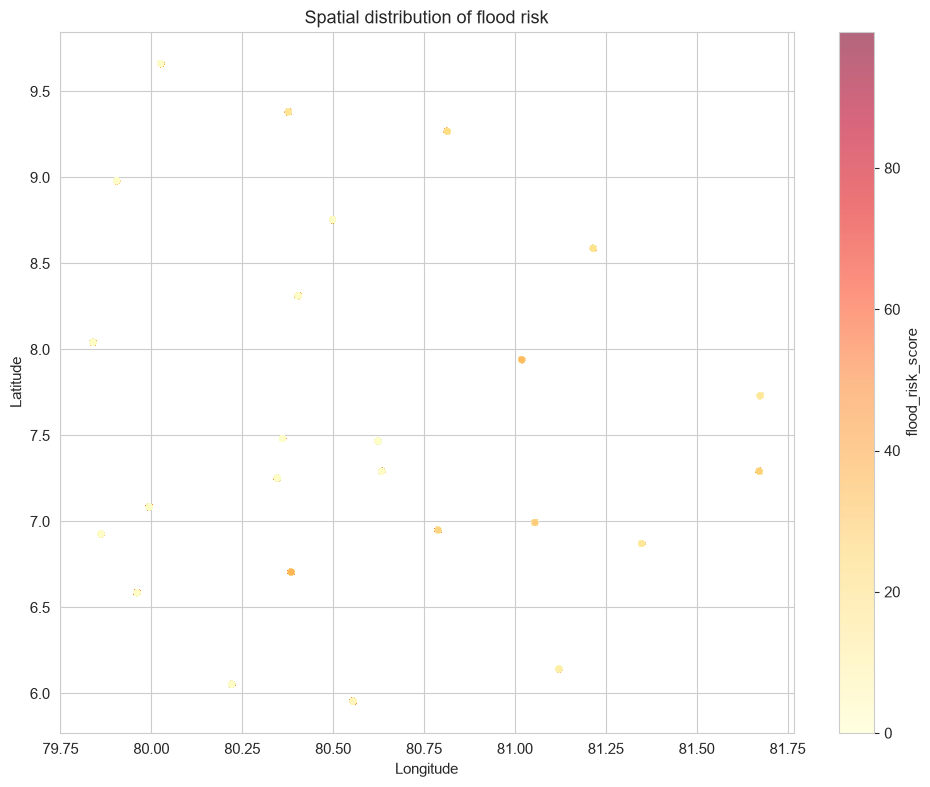

In [20]:
# Map (scatter by lat/lon)
plt.figure(figsize=(10, 8))
sc = plt.scatter(df['longitude'], df['latitude'],
                 c=df['flood_risk_score'], cmap='YlOrRd',
                 s=25, alpha=0.6, edgecolors='none')
plt.colorbar(sc, label='flood_risk_score')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.title('Spatial distribution of flood risk')
plt.tight_layout()
plt.show()

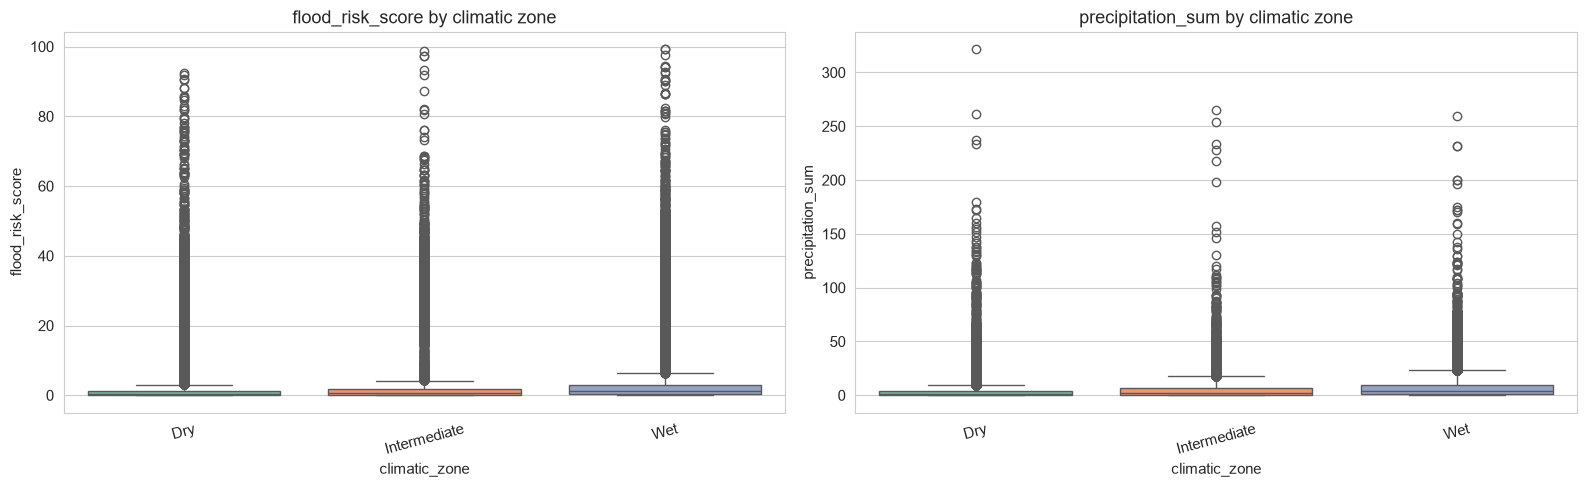

In [21]:
# -------------------------------------------------------------
# 8. CLIMATIC ZONES
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=df, x='climatic_zone', y='flood_risk_score', ax=axes[0], palette='Set2')
axes[0].set_title('flood_risk_score by climatic zone')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=df, x='climatic_zone', y='precipitation_sum', ax=axes[1], palette='Set2')
axes[1].set_title('precipitation_sum by climatic zone')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

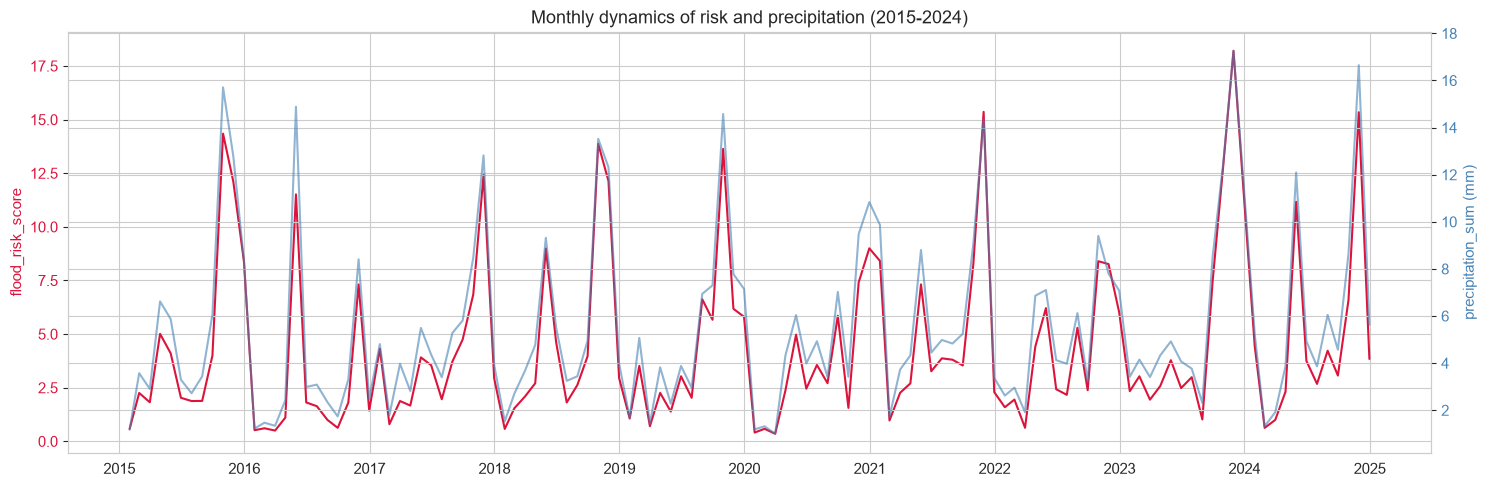

In [23]:
# -------------------------------------------------------------
# 9. TEMPORAL DYNAMICS
# -------------------------------------------------------------
monthly = df.set_index('date').resample('ME').agg(
    flood_risk_score=('flood_risk_score', 'mean'),
    precipitation_sum=('precipitation_sum', 'mean'),
    soil_saturation=('soil_saturation_index', 'mean')
)

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(monthly.index, monthly['flood_risk_score'], color='crimson', label='flood_risk_score')
ax1.set_ylabel('flood_risk_score', color='crimson')
ax1.tick_params(axis='y', labelcolor='crimson')

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly['precipitation_sum'], color='steelblue', alpha=0.6,
         label='precipitation_sum')
ax2.set_ylabel('precipitation_sum (mm)', color='steelblue')
ax2.tick_params(axis='y', labelcolor='steelblue')

plt.title('Monthly dynamics of risk and precipitation (2015-2024)')
plt.tight_layout()
plt.show()

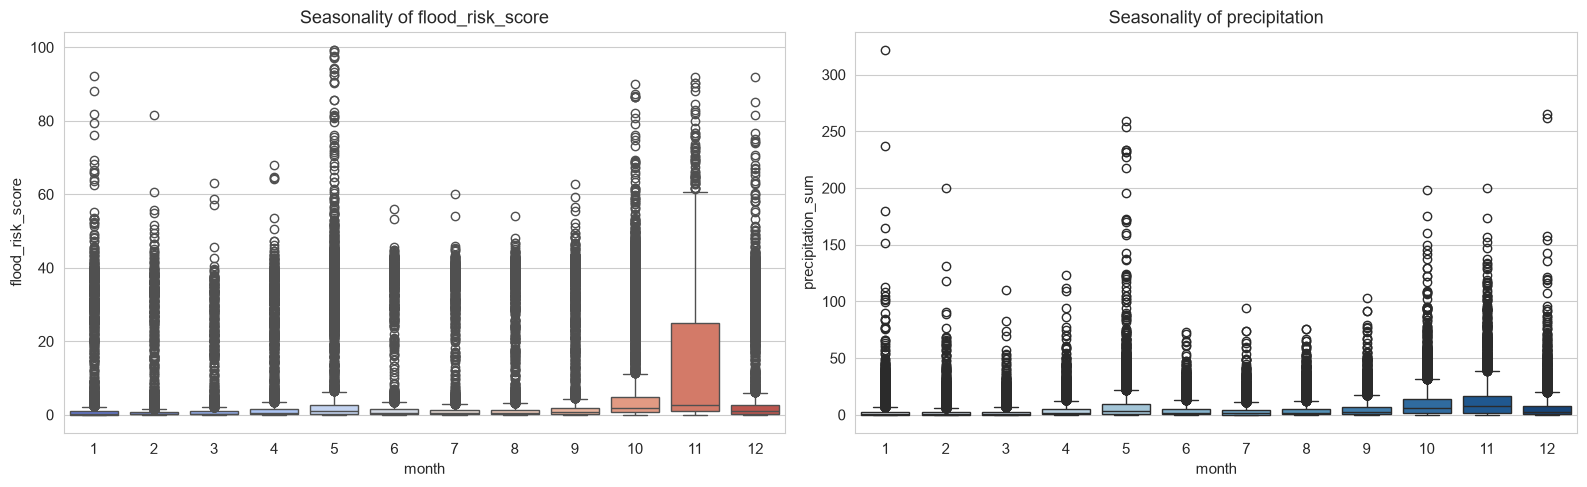

In [24]:
# Seasonality by month
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.strftime('%b')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x='month', y='flood_risk_score', ax=axes[0], palette='coolwarm')
axes[0].set_title('Seasonality of flood_risk_score')

sns.boxplot(data=df, x='month', y='precipitation_sum', ax=axes[1], palette='Blues')
axes[1].set_title('Seasonality of precipitation')

plt.tight_layout()
plt.show()

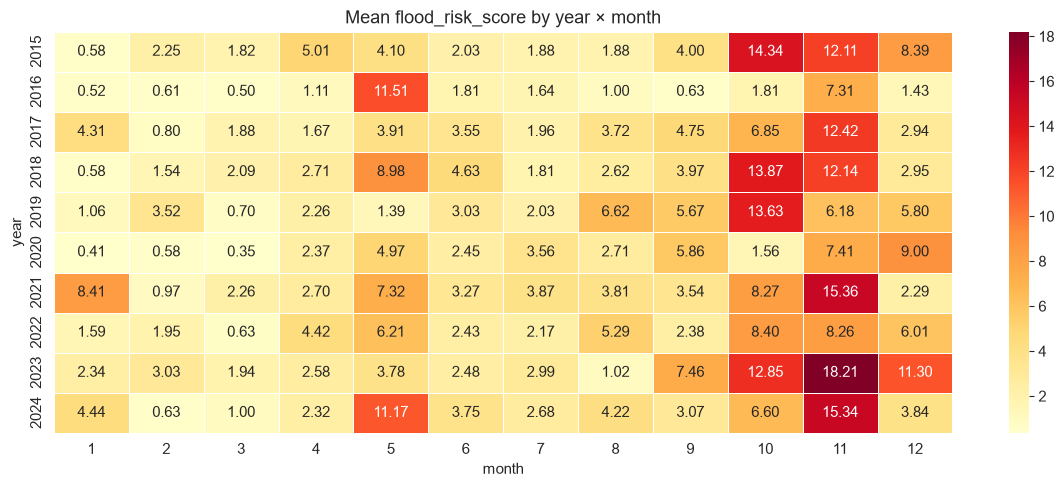

In [25]:
# Heatmap year × month
pivot = df.pivot_table(index='year', columns='month',
                       values='flood_risk_score', aggfunc='mean')
plt.figure(figsize=(12, 5))
sns.heatmap(pivot, cmap='YlOrRd', annot=True, fmt='.2f', linewidths=0.5)
plt.title('Mean flood_risk_score by year × month')
plt.tight_layout()
plt.show()

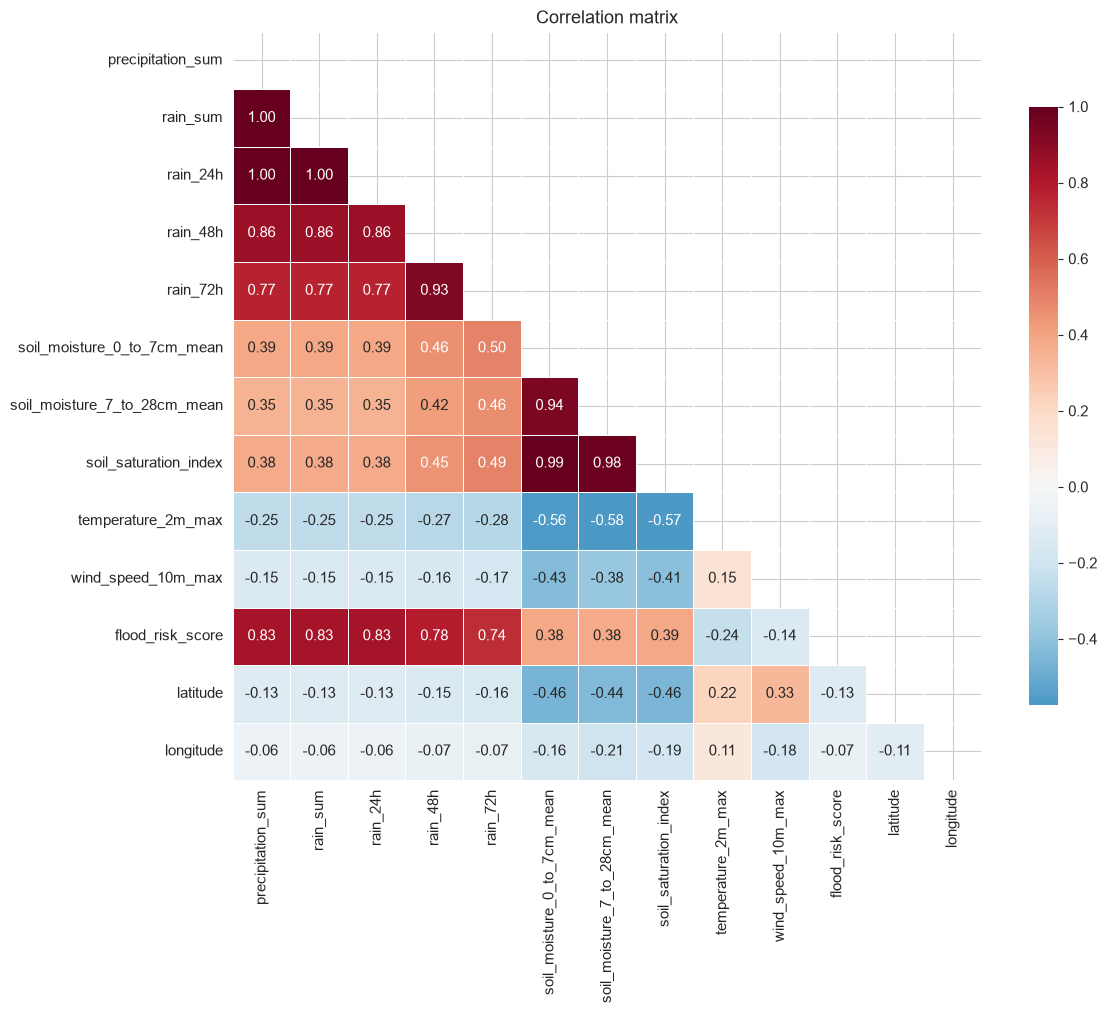

In [26]:
# -------------------------------------------------------------
# 10. CORRELATIONS
# -------------------------------------------------------------
corr_cols = num_cols + ['latitude', 'longitude']
corr = df[corr_cols].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()


=== Correlations with flood_risk_score ===
precipitation_sum               0.831
rain_sum                        0.831
rain_24h                        0.831
rain_48h                        0.783
rain_72h                        0.737
soil_saturation_index           0.387
soil_moisture_0_to_7cm_mean     0.385
soil_moisture_7_to_28cm_mean    0.377
temperature_2m_max             -0.241
wind_speed_10m_max             -0.140
latitude                       -0.131
longitude                      -0.067
Name: flood_risk_score, dtype: float64


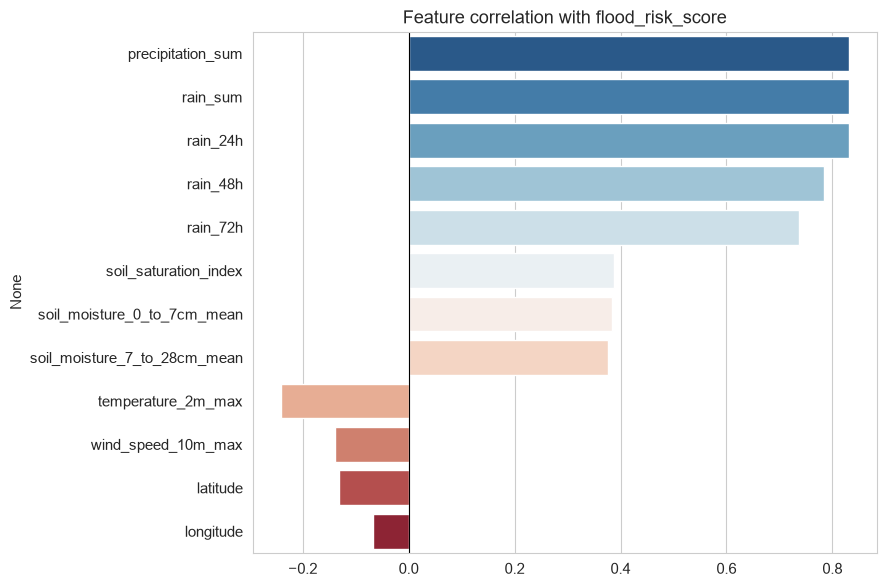

In [27]:
# Top correlations with target variable
target_corr = df[corr_cols].corr()['flood_risk_score'].drop('flood_risk_score')
target_corr = target_corr.sort_values(key=abs, ascending=False)
print('\n=== Correlations with flood_risk_score ===')
print(target_corr)

plt.figure(figsize=(9, 6))
sns.barplot(x=target_corr.values, y=target_corr.index,
            palette='RdBu_r', orient='h')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Feature correlation with flood_risk_score')
plt.tight_layout()
plt.show()


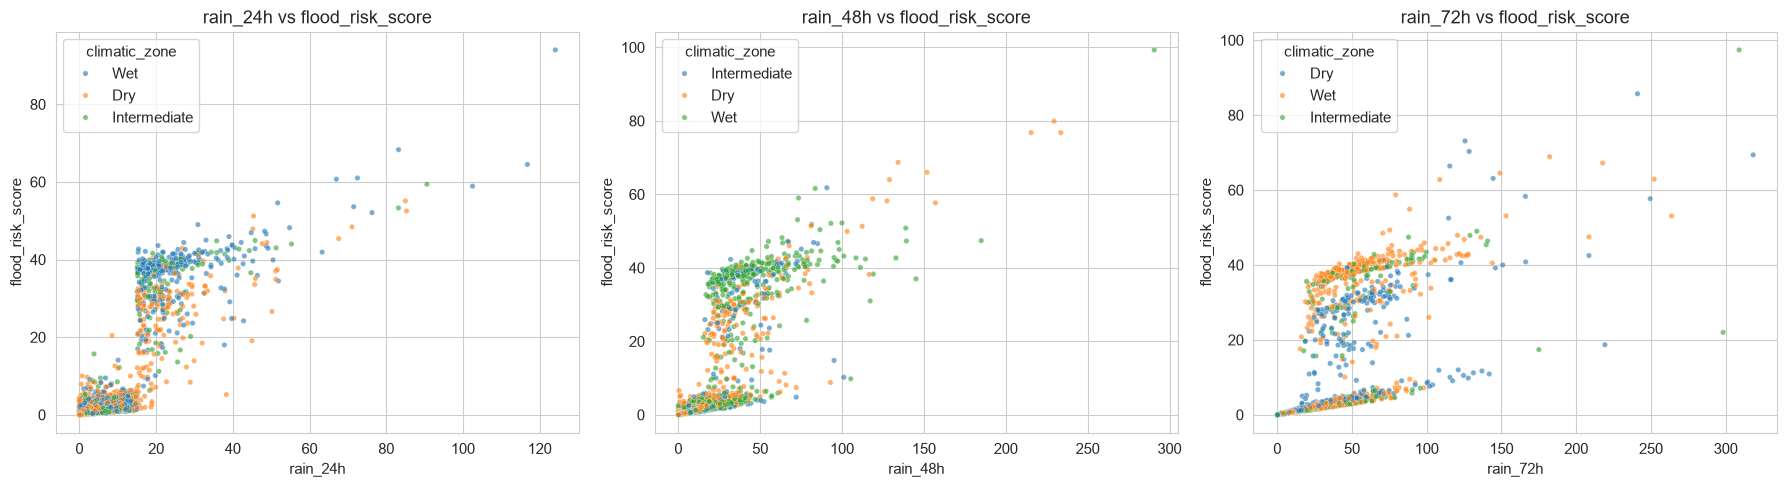

In [28]:
# -------------------------------------------------------------
# 11. RELATIONSHIP BETWEEN PRECIPITATION AND RISK
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['rain_24h', 'rain_48h', 'rain_72h']):
    sns.scatterplot(data=df.sample(min(5000, len(df))),
                    x=col, y='flood_risk_score',
                    hue='climatic_zone', ax=axes[i], s=15, alpha=0.6)
    axes[i].set_title(f'{col} vs flood_risk_score')
plt.tight_layout()
plt.show()

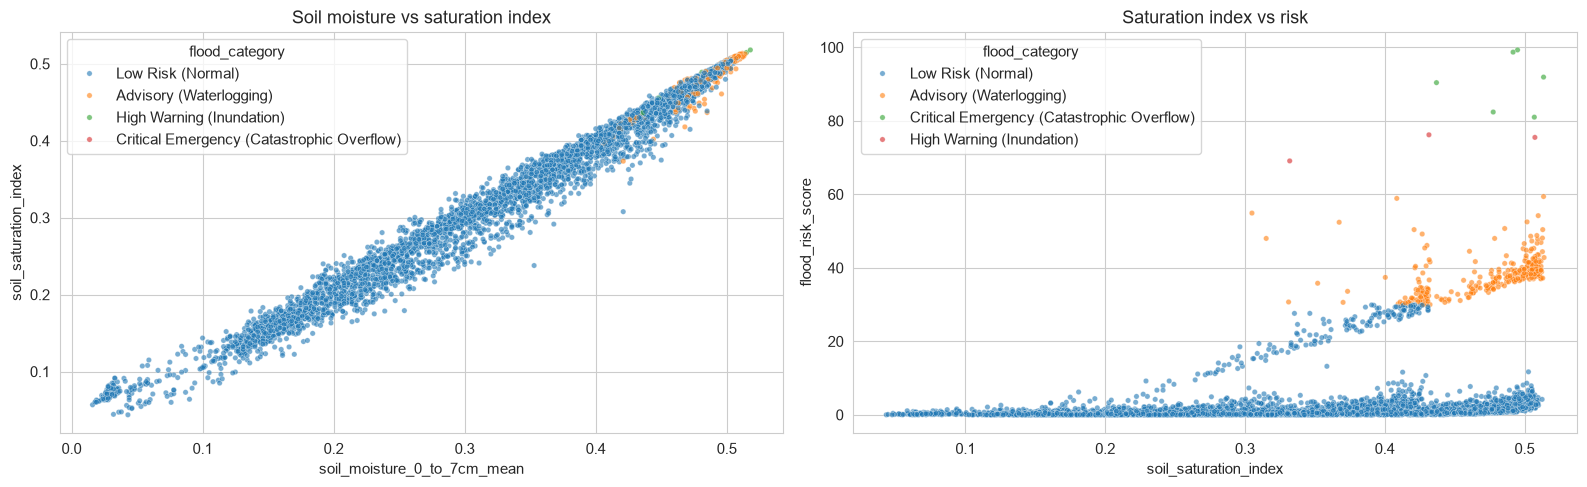

In [29]:
# -------------------------------------------------------------
# 12. SOIL MOISTURE AND SATURATION
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=df.sample(min(5000, len(df))),
                x='soil_moisture_0_to_7cm_mean', y='soil_saturation_index',
                hue='flood_category', ax=axes[0], s=15, alpha=0.6)
axes[0].set_title('Soil moisture vs saturation index')

sns.scatterplot(data=df.sample(min(5000, len(df))),
                x='soil_saturation_index', y='flood_risk_score',
                hue='flood_category', ax=axes[1], s=15, alpha=0.6)
axes[1].set_title('Saturation index vs risk')
plt.tight_layout()
plt.show()

In [30]:
# -------------------------------------------------------------
# 13. OUTLIERS (IQR)
# -------------------------------------------------------------
print('\n=== Outliers by IQR ===')
out_summary = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    out_summary.append({'feature': col, 'n_outliers': n_out,
                        'pct': round(n_out / len(df) * 100, 2),
                        'low': low, 'high': high})
display(pd.DataFrame(out_summary))


=== Outliers by IQR ===


,feature,n_outliers,pct,low,high
0,precipitation_sum,8369,9.160,-9.550,16.450
1,rain_sum,8369,9.160,-9.550,16.450
2,rain_24h,8369,9.160,-9.550,16.450
3,rain_48h,6704,7.340,-19.650,35.150
4,rain_72h,6103,6.680,-29.250,53.550
5,soil_moisture_0_to_7cm_mean,0,0.000,-0.082,0.758
6,soil_moisture_7_to_28cm_mean,0,0.000,-0.087,0.740
7,soil_saturation_index,0,0.000,-0.078,0.743
8,temperature_2m_max,5095,5.580,23.450,36.650
9,wind_speed_10m_max,1746,1.910,-1.250,34.350


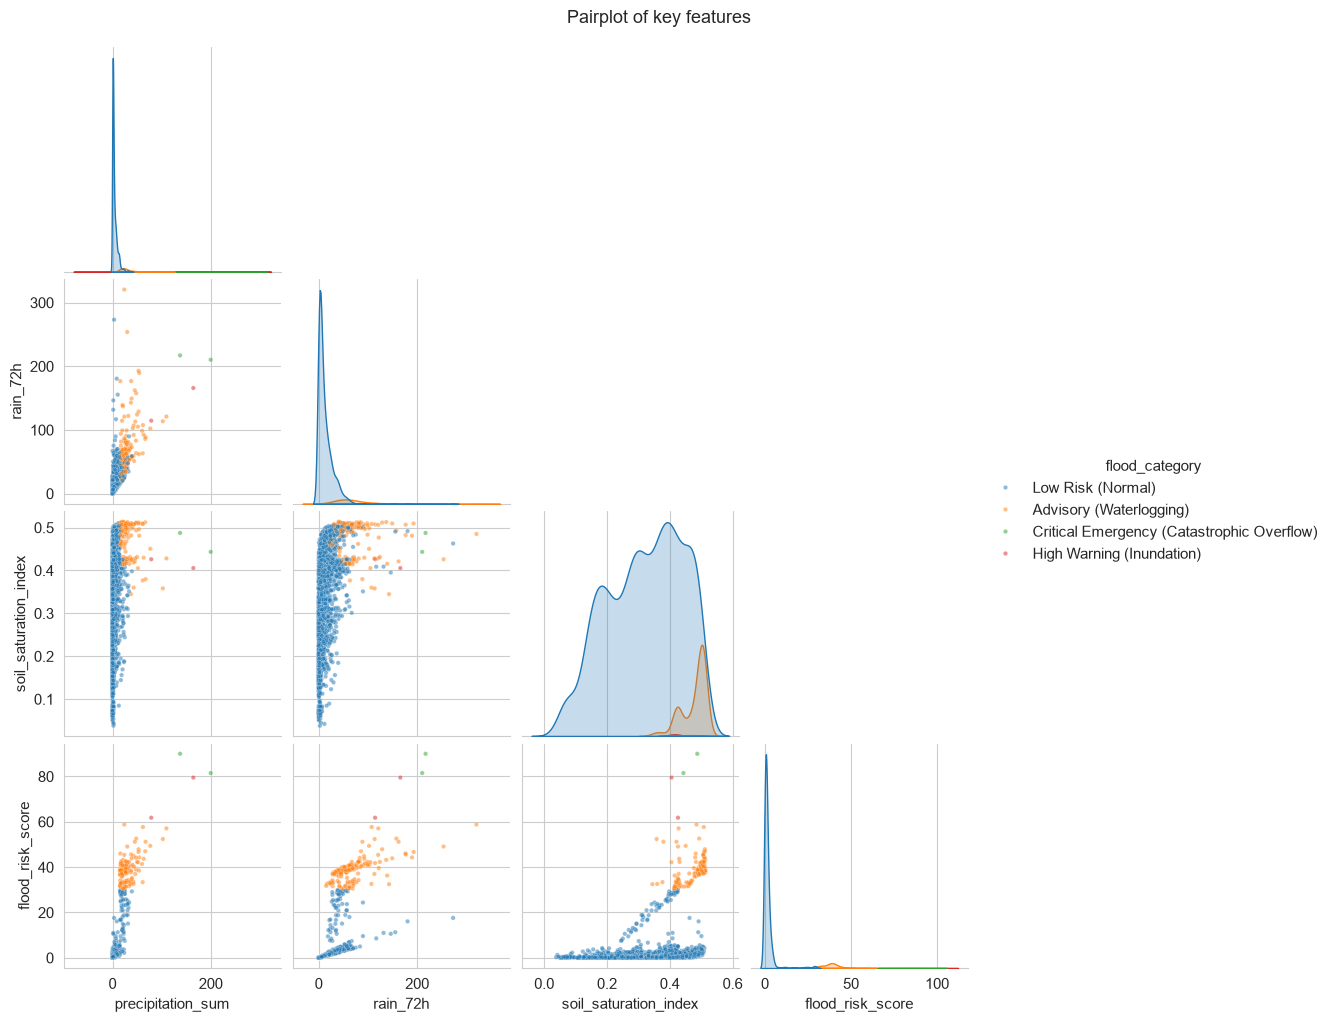

In [31]:
# -------------------------------------------------------------
# 14. PAIRWISE RELATIONSHIPS 
# -------------------------------------------------------------
sample = df.sample(min(2000, len(df)), random_state=42)
pair_cols = ['precipitation_sum', 'rain_72h', 'soil_saturation_index',
             'flood_risk_score', 'flood_category']
sns.pairplot(sample[pair_cols], hue='flood_category',
             corner=True, diag_kind='kde', plot_kws={'s': 10, 'alpha': 0.5})
plt.suptitle('Pairplot of key features', y=1.02)
plt.show()

In [32]:
# -------------------------------------------------------------
# 15. FINAL SUMMARY
# -------------------------------------------------------------
print('\n' + '=' * 60)
print('EDA SUMMARY')
print('=' * 60)
print(f'Rows: {len(df):,}')
print(f'Features: {df.shape[1]}')
print(f'Districts: {df["district"].nunique()}')
print(f'Provinces: {df["province"].nunique()}')
print(f'Climatic zones: {df["climatic_zone"].nunique()}')
print(f'Period: {df["date"].min().date()} — {df["date"].max().date()}')
print(f'Missing values: {df.isna().sum().sum()}')
print(f'Target variable: flood_category ({df["flood_category"].nunique()} classes)')
print(f'Strongest correlation with risk: '
      f'{target_corr.abs().idxmax()} ({target_corr.abs().max():.3f})')
print('=' * 60)


EDA SUMMARY
Rows: 91,325
Features: 21
Districts: 25
Provinces: 9
Climatic zones: 3
Period: 2015-01-01 — 2024-12-31
Missing values: 0
Target variable: flood_category (4 classes)
Strongest correlation with risk: precipitation_sum (0.831)
